# 03 · Modelo de clasificación: ¿llegará tarde el pedido?

**La pregunta:** cuando alguien compra, ¿podemos saber si su pedido va a llegar **después de la fecha que le prometieron**?

La respuesta es "sí" o "no", así que es un problema de **clasificación**. Usamos los mismos pedidos, las mismas variables y la misma división por fecha que en el cuaderno 02. Lo que queremos predecir es `tarde`, que vale 1 si el pedido llegó después del día prometido.

**El gran desafío:** solo el 6,8% de los pedidos llega tarde. Un modelo que siempre diga "a tiempo" acertaría el 93% de las veces sin servir para nada. Por eso miramos varias métricas:

- **Matriz de confusión:** una tabla que cuenta aciertos y errores: retrasos detectados, falsas alarmas, retrasos que se le escaparon al modelo y pedidos a tiempo bien clasificados.
- **Exactitud (*accuracy*):** el porcentaje de aciertos. Engaña cuando hay pocos retrasos.
- **Precisión:** de los pedidos que el modelo marca como "tarde", cuántos llegaron tarde de verdad.
- ***Recall* (exhaustividad):** de los pedidos que llegaron tarde, cuántos detectó el modelo.
- **F1:** junta la precisión y el *recall* en un solo número; solo es alto si las dos son buenas.
- **AUC-ROC:** qué tan bien ordena el modelo los pedidos según su riesgo. Si tomamos un pedido que llegó tarde y otro que llegó a tiempo, el AUC es la probabilidad de que el modelo le dé más riesgo al que llegó tarde. Un 0,5 es como lanzar una moneda y un 1 sería perfecto.

**Pasos que seguimos:** los mismos del cuaderno 02, más uno nuevo: elegir el **umbral**, es decir, la probabilidad desde la cual decimos que un pedido "va a llegar tarde".

**Cómo ejecutarlo:** igual que los cuadernos anteriores. Primero hay que ejecutar el cuaderno 01. En el computador tarda unos minutos; en Colab puede tardar bastante más.

In [1]:
# Importamos las librerías. Ahora usamos los modelos de clasificación y sus métricas
import json
import sys
import time
from datetime import date
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from cycler import cycler
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

# Si estamos en Colab, leemos los datos desde Google Drive; si no, desde la carpeta del proyecto
EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/proyecto")  # cambiar si la carpeta está en otra ubicación de Drive
else:
    BASE = Path("..")

ARCHIVO = BASE / "data" / "processed" / "pedidos_entregados.csv"
MODELOS = BASE / "models"
if not ARCHIVO.exists():
    raise FileNotFoundError(f"No se encontró {ARCHIVO.resolve()}. Ejecuta primero el cuaderno 01.")
MODELOS.mkdir(exist_ok=True)
SEMILLA = 42  # fijamos la "semilla" del azar para que los resultados salgan iguales cada vez
print(f"scikit-learn {sklearn.__version__} · datos: {ARCHIVO.resolve()}")

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:.3f}".format)

# Los mismos colores que en los cuadernos anteriores
SUPERFICIE, TINTA, TINTA_2, TENUE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRILLA, EJE = "#e1e0d9", "#c3c2b7"
AZUL, NARANJA, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "figure.figsize": (10, 4), "figure.dpi": 110,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": TINTA, "axes.titlecolor": TINTA, "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.labelcolor": TINTA_2, "axes.edgecolor": EJE, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRILLA, "grid.linewidth": 0.6,
    "xtick.color": EJE, "ytick.color": EJE, "xtick.labelcolor": TINTA_2, "ytick.labelcolor": TINTA_2,
    "legend.frameon": False, "lines.linewidth": 2,
    "axes.prop_cycle": cycler(color=[AZUL, NARANJA, AQUA]),
})

scikit-learn 1.9.1 · datos: D:\Buri\proyecto\data\processed\pedidos_entregados.csv


In [2]:
# Cargamos los pedidos limpios y los ordenamos por fecha de compra
df = pd.read_csv(ARCHIVO, parse_dates=["order_purchase_timestamp", "order_estimated_delivery_date",
                                       "order_delivered_customer_date"])
df = df.sort_values("order_purchase_timestamp").reset_index(drop=True)
print(f"{len(df)} pedidos · llegaron tarde: {df['tarde'].sum()} ({df['tarde'].mean():.1%})")

89713 pedidos · llegaron tarde: 6136 (6.8%)


## 1. Variables y división por fecha

Usamos **las mismas variables que en el cuaderno 02**, todas conocidas en el momento de la compra, y por la misma razón dejamos fuera el mes. También repetimos la división por fecha: entrenamiento de enero de 2017 a febrero de 2018, validación en marzo y abril de 2018 y prueba de mayo a julio de 2018.

In [3]:
# Variables para predecir (X), lo que queremos predecir (y) y la división por fecha
CATEGORICAS = ["customer_state", "seller_state", "categoria", "tipo_pago", "dia_semana"]
NUMERICAS = ["distancia_km", "mismo_estado", "dias_prometidos", "flete_total", "precio_total",
             "peso_total_g", "volumen_total_cm3", "n_items", "n_vendedores", "cuotas", "hora"]
OBJETIVO = "tarde"
X = df[CATEGORICAS + NUMERICAS]
y = df[OBJETIVO]

fecha = df["order_purchase_timestamp"]
mascaras = {
    "entrenamiento": fecha < pd.Timestamp("2018-03-01"),
    "validación": (fecha >= pd.Timestamp("2018-03-01")) & (fecha < pd.Timestamp("2018-05-01")),
    "prueba": fecha >= pd.Timestamp("2018-05-01"),
}
X_ent, y_ent = X[mascaras["entrenamiento"]], y[mascaras["entrenamiento"]]
X_val, y_val = X[mascaras["validación"]], y[mascaras["validación"]]
X_pru, y_pru = X[mascaras["prueba"]], y[mascaras["prueba"]]

pd.DataFrame({
    nombre: {"pedidos": int(m.sum()), "pedidos tarde": int(y[m].sum()), "% tarde": 100 * y[m].mean(),
             "desde": fecha[m].min().date(), "hasta": fecha[m].max().date()}
    for nombre, m in mascaras.items()
}).T

,pedidos,pedidos tarde,% tarde,desde,hasta
entrenamiento,57031,3782,6.631,2017-01-05,2018-02-28
validación,13794,1634,11.846,2018-03-01,2018-04-30
prueba,18888,720,3.812,2018-05-01,2018-07-31


**¿Qué vemos?** El porcentaje de pedidos tarde cambia mucho entre los conjuntos: 6,6% en entrenamiento, 11,8% en validación y solo 3,8% en prueba. Es lo que vimos en el cuaderno 01: marzo de 2018 tuvo muchos retrasos y junio de 2018 casi ninguno. Esto hace más difícil la prueba, porque el modelo aprende con un período y se evalúa en otro muy distinto.

## 2. ¿Qué resultado hay que superar? (*baselines*)

- **Siempre a tiempo:** el modelo más perezoso posible, que nunca predice un retraso.
- **Riesgo por estado:** le da a cada pedido el porcentaje de retrasos que tuvo su estado en el entrenamiento. Por ejemplo, si en Alagoas llegó tarde el 22% de los pedidos, a un pedido para Alagoas le da un 22% de riesgo.

**¿Cómo pasamos de una probabilidad a un "sí" o "no"?** Los modelos dan una probabilidad de llegar tarde. Para decidir, elegimos un **umbral**: si la probabilidad es mayor o igual al umbral, decimos "tarde". Como los retrasos son pocos, el umbral típico de 0,5 casi nunca se alcanza. Por eso, para cada modelo, elegimos el umbral que da **el mejor F1 en validación**, y lo aplicamos igual a todos para que la comparación sea justa.

In [4]:
# Funciones: elegir el umbral con el mejor F1 y calcular todas las métricas
def mejor_umbral(y_real, prob):
    """Devuelve el umbral de probabilidad que da el mayor F1."""
    precision, recall, umbrales = precision_recall_curve(y_real, prob)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    return float(umbrales[int(np.argmax(f1[:-1]))])  # el último punto de la curva no tiene umbral


def metricas(y_real, prob, umbral):
    pred = (prob >= umbral).astype(int)
    return {"exactitud": accuracy_score(y_real, pred),
            "precisión": precision_score(y_real, pred, zero_division=0),
            "recall": recall_score(y_real, pred, zero_division=0),
            "F1": f1_score(y_real, pred, zero_division=0),
            "AUC": roc_auc_score(y_real, prob)}


# Los baselines se calculan solo con los datos de entrenamiento
def crear_baselines(X_ajuste, y_ajuste):
    tasa = y_ajuste.mean()
    por_estado = y_ajuste.groupby(X_ajuste["customer_state"]).mean()
    return {
        "Siempre a tiempo": lambda Xc: np.zeros(len(Xc)),
        "Riesgo por estado": lambda Xc: Xc["customer_state"].map(por_estado).fillna(tasa).to_numpy(),
    }


baselines = crear_baselines(X_ent, y_ent)
umbrales = {"Siempre a tiempo": 0.5,  # nunca predice "tarde"
            "Riesgo por estado": mejor_umbral(y_val, baselines["Riesgo por estado"](X_val))}
filas = []
for nombre, predecir in baselines.items():
    for conjunto, (Xc, yc) in {"entrenamiento": (X_ent, y_ent), "validación": (X_val, y_val)}.items():
        filas.append({"modelo": nombre, "conjunto": conjunto, "umbral": umbrales[nombre],
                      **metricas(yc, predecir(Xc), umbrales[nombre])})
pd.DataFrame(filas).set_index(["modelo", "conjunto"])

umbral  exactitud  precisión  recall    F1  \
modelo            conjunto                                                    
Siempre a tiempo  entrenamiento   0.500      0.934      0.000   0.000 0.000   
                  validación      0.500      0.882      0.000   0.000 0.000   
Riesgo por estado entrenamiento   0.072      0.699      0.118   0.549 0.195   
                  validación      0.072      0.726      0.222   0.523 0.312   

                                  AUC  
modelo            conjunto             
Siempre a tiempo  entrenamiento 0.500  
                  validación    0.500  
Riesgo por estado entrenamiento 0.656  
                  validación    0.637

**¿Qué vemos?**

- **Siempre a tiempo** acierta el 88% de los pedidos de validación, pero no detecta ni un retraso: su *recall* y su F1 son 0. Por eso la exactitud sola no sirve en este problema.
- **Riesgo por estado** ya ordena mejor que el azar (AUC de 0,64 en validación). Con un umbral de 0,072 detecta el 52% de los retrasos, pero solo el 22% de sus alertas son correctas (F1 de 0,31).

**Nuestra meta:** superar en validación el AUC de 0,64 y el F1 de 0,31.

## 3. Preparación de los datos y algoritmos

La preparación es la misma del cuaderno 02 y también va dentro de un **Pipeline**, la "receta" que se guarda junto con el modelo: se rellenan los vacíos, las categorías se convierten en números y, para el modelo lineal, los números se ponen en la misma escala.

**¿Por qué no le damos más peso a los pedidos tarde?** Una forma común de enfrentar el desbalance es darles más peso a los pedidos tarde al entrenar. Nosotros preferimos entrenar normalmente y después **elegir el umbral**. Así la probabilidad que da el modelo sigue teniendo sentido: si dice 10%, más o menos 1 de cada 10 pedidos parecidos llega tarde. Esa probabilidad es la que vamos a mostrar en la aplicación.

| Algoritmo | ¿Cómo funciona? | Hiperparámetros que probamos |
|---|---|---|
| **Regresión logística** | Un modelo lineal que convierte una suma de variables en una probabilidad entre 0 y 1 | `C` (lo contrario de la regularización: un `C` chico es un modelo más simple): 0,01 · 0,1 · 1 · 10 |
| **Random Forest** | Muchos árboles de decisión que votan; la probabilidad es la proporción de votos | `max_depth`: 8 · 12 · 16. `min_samples_leaf`: 20 · 50. `max_features`: 0,3 · 0,6 (150 árboles) |
| **Gradient Boosting** | Árboles uno detrás de otro, cada uno corrige los errores del anterior | `learning_rate`: 0,03 · 0,1. `max_leaf_nodes`: 15 · 31. `min_samples_leaf`: 50 · 200. `l2_regularization`: 0 · 1 |

Elegimos estos tres para comparar un modelo lineal con dos modelos de árboles, igual que en la regresión. La búsqueda es igual que en el cuaderno 02: todos los valores para la regresión logística y combinaciones al azar para los otros dos (6 y 8), con **validación cruzada temporal** de 4 rondas. Esta vez elegimos la combinación con el **mayor AUC**, porque mide qué tan bien ordena el modelo los pedidos por riesgo sin depender del umbral.

In [5]:
# Recetas de preparación (las mismas del cuaderno 02)
def prep_onehot(categoricas, numericas):
    """Rellena vacíos, convierte las categorías en columnas de 0 y 1 y pone los números en la misma escala."""
    return ColumnTransformer([
        ("categoricas", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")),
         categoricas),
        ("numericas", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numericas),
    ])


def prep_ordinal(categoricas, numericas):
    """Rellena vacíos en las categorías y las convierte en códigos; los números pasan tal cual."""
    return ColumnTransformer([
        ("categoricas", make_pipeline(SimpleImputer(strategy="most_frequent"),
                                      OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan)),
         categoricas),
        ("numericas", "passthrough", numericas),
    ])


cv_temporal = TimeSeriesSplit(n_splits=4)


# Para cada algoritmo: su receta, los hiperparámetros a probar y cuántas combinaciones probar
def crear_candidatos(categoricas, numericas):
    return {
        "Regresión logística": (
            Pipeline([("prep", prep_onehot(categoricas, numericas)), ("modelo", LogisticRegression(max_iter=2000))]),
            {"modelo__C": [0.01, 0.1, 1, 10]},
            None,  # búsqueda en malla completa
        ),
        "Random Forest": (
            Pipeline([("prep", prep_onehot(categoricas, numericas)),
                      ("modelo", RandomForestClassifier(n_estimators=150, max_samples=0.5, n_jobs=-1,
                                                        random_state=SEMILLA))]),
            {"modelo__max_depth": [8, 12, 16], "modelo__min_samples_leaf": [20, 50],
             "modelo__max_features": [0.3, 0.6]},
            6,
        ),
        "Gradient Boosting": (
            Pipeline([("prep", prep_ordinal(categoricas, numericas)),
                      ("modelo", HistGradientBoostingClassifier(categorical_features=list(range(len(categoricas))),
                                                                max_iter=500, early_stopping=True,
                                                                random_state=SEMILLA))]),
            {"modelo__learning_rate": [0.03, 0.1], "modelo__max_leaf_nodes": [15, 31],
             "modelo__min_samples_leaf": [50, 200], "modelo__l2_regularization": [0.0, 1.0]},
            8,
        ),
    }


# Buscamos la mejor configuración de cada algoritmo (esta es la celda que más tarda)
busquedas = {}
for nombre, (modelo, grilla, n_iter) in crear_candidatos(CATEGORICAS, NUMERICAS).items():
    inicio = time.time()
    if n_iter is None:
        busqueda = GridSearchCV(modelo, grilla, cv=cv_temporal, scoring="roc_auc", return_train_score=True)
    else:
        busqueda = RandomizedSearchCV(modelo, grilla, n_iter=n_iter, cv=cv_temporal, scoring="roc_auc",
                                      return_train_score=True, random_state=SEMILLA)
    busqueda.fit(X_ent, y_ent)
    busquedas[nombre] = busqueda
    mejores = {k.replace("modelo__", ""): v for k, v in busqueda.best_params_.items()}
    print(f"{nombre}: AUC en validación cruzada = {busqueda.best_score_:.3f} "
          f"({time.time() - inicio:.0f} s) · mejor configuración: {mejores}")

Regresión logística: AUC en validación cruzada = 0.679 (6 s) · mejor configuración: {'C': 0.01}


Random Forest: AUC en validación cruzada = 0.652 (52 s) · mejor configuración: {'min_samples_leaf': 50, 'max_features': 0.3, 'max_depth': 12}


Gradient Boosting: AUC en validación cruzada = 0.644 (18 s) · mejor configuración: {'min_samples_leaf': 200, 'max_leaf_nodes': 15, 'learning_rate': 0.03, 'l2_regularization': 1.0}


### Resultados de la búsqueda

Para cada combinación vemos el AUC promedio con los datos con que entrenó y con los de validación. Si el AUC de entrenamiento es mucho mayor que el de validación, el modelo está memorizando (**sobreajuste**).

In [6]:
# Tabla con todas las combinaciones probadas, ordenadas de mejor a peor
def tabla_cv(busqueda):
    r = pd.DataFrame(busqueda.cv_results_)
    params = [c for c in r.columns if c.startswith("param_")]
    t = r[params + ["mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"]].copy()
    t.columns = ([c.replace("param_modelo__", "") for c in params]
                 + ["AUC entrenamiento", "AUC validación", "desviación", "ranking"])
    return t.sort_values("ranking").set_index("ranking")


for nombre, busqueda in busquedas.items():
    print(f"\n{nombre}")
    display(tabla_cv(busqueda))


Regresión logística


,C,AUC entrenamiento,AUC validación,desviación
ranking,,,,
1,0.010,0.677,0.679,0.027
2,0.100,0.695,0.672,0.027
3,1.000,0.702,0.664,0.030
4,10.000,0.705,0.659,0.032



Random Forest


,min_samples_leaf,max_features,max_depth,AUC entrenamiento,AUC validación,desviación
ranking,,,,,,
1,50,0.300,12,0.808,0.652,0.031
2,50,0.300,16,0.832,0.650,0.033
3,20,0.300,8,0.779,0.649,0.033
4,20,0.300,16,0.893,0.648,0.030
5,20,0.600,8,0.780,0.648,0.034
6,20,0.600,16,0.904,0.644,0.032



Gradient Boosting


,min_samples_leaf,max_leaf_nodes,learning_rate,l2_regularization,AUC entrenamiento,AUC validación,desviación
ranking,,,,,,,
1,200,15,0.030,1.000,0.796,0.644,0.042
2,200,15,0.100,0.000,0.809,0.643,0.042
3,50,15,0.030,0.000,0.792,0.642,0.041
4,200,15,0.030,0.000,0.807,0.642,0.041
5,200,15,0.100,1.000,0.816,0.641,0.042
6,200,31,0.030,1.000,0.850,0.640,0.043
7,50,15,0.030,1.000,0.788,0.639,0.043
8,50,31,0.100,1.000,0.867,0.639,0.042


**¿Qué vemos?**

- La **regresión logística**, el modelo más simple, gana en la validación cruzada (AUC de 0,68), seguida de Random Forest (0,65) y Gradient Boosting (0,64).
- Los dos modelos de árboles tienen un AUC de entrenamiento mucho más alto que el de validación (entre 0,79 y 0,90, contra 0,64–0,65): **memorizan** el entrenamiento. Con señales tan débiles, aprenden detalles que no se repiten.
- En la regresión logística gana el `C` más chico (0,01), es decir, el modelo más simple y con más regularización. Su AUC de entrenamiento y el de validación son casi iguales (0,68): no se sobreajusta.

## 4. Comparamos los modelos con los datos de validación

Entrenamos cada algoritmo con su mejor configuración usando todo el entrenamiento, elegimos su umbral en validación y calculamos todas las métricas.

In [7]:
# Probabilidades, umbral y métricas de cada modelo en entrenamiento y validación
probs_val = {nombre: b.predict_proba(X_val)[:, 1] for nombre, b in busquedas.items()}
for nombre, b in busquedas.items():
    umbrales[nombre] = mejor_umbral(y_val, probs_val[nombre])
    for conjunto, (Xc, yc) in {"entrenamiento": (X_ent, y_ent), "validación": (X_val, y_val)}.items():
        filas.append({"modelo": nombre, "conjunto": conjunto, "umbral": umbrales[nombre],
                      **metricas(yc, b.predict_proba(Xc)[:, 1], umbrales[nombre])})
comparacion = pd.DataFrame(filas).set_index(["modelo", "conjunto"])
mejor_nombre = comparacion.xs("validación", level="conjunto").loc[list(busquedas), "AUC"].idxmax()
print(f"Mejor modelo en validación (mayor AUC): {mejor_nombre}")
comparacion

Mejor modelo en validación (mayor AUC): Regresión logística


umbral  exactitud  precisión  recall    F1  \
modelo              conjunto                                                    
Siempre a tiempo    entrenamiento   0.500      0.934      0.000   0.000 0.000   
                    validación      0.500      0.882      0.000   0.000 0.000   
Riesgo por estado   entrenamiento   0.072      0.699      0.118   0.549 0.195   
                    validación      0.072      0.726      0.222   0.523 0.312   
Regresión logística entrenamiento   0.095      0.791      0.148   0.453 0.223   
                    validación      0.095      0.799      0.292   0.490 0.366   
Random Forest       entrenamiento   0.104      0.835      0.188   0.447 0.265   
                    validación      0.104      0.819      0.303   0.408 0.348   
Gradient Boosting   entrenamiento   0.119      0.857      0.214   0.432 0.286   
                    validación      0.119      0.828      0.313   0.377 0.342   

                                    AUC  
modelo              conjunto             
Siempre a tiempo    entrenamiento 0.500  
                    validación    0.500  
Riesgo por estado   entrenamiento 0.656  
                    validación    0.637  
Regresión logística entrenamiento 0.696  
                    validación    0.745  
Random Forest       entrenamiento 0.781  
                    validación    0.718  
Gradient Boosting   entrenamiento 0.770  
                    validación    0.724

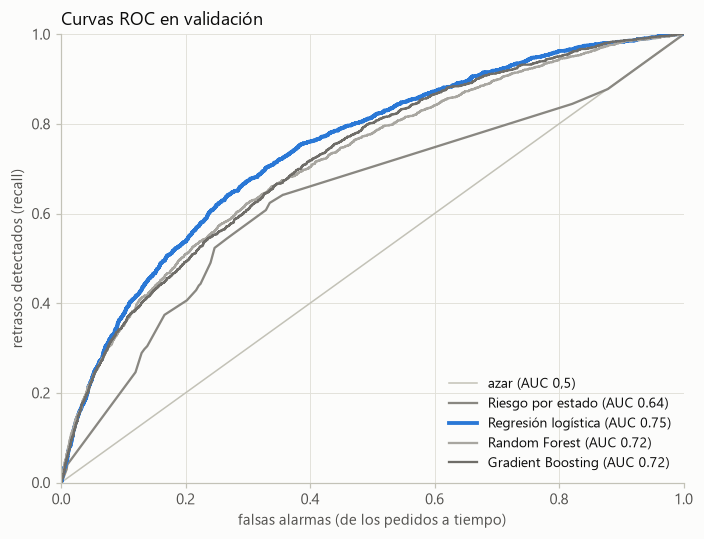

In [8]:
# Curvas ROC en validación: cuanto más se acerca la curva a la esquina de arriba a la izquierda, mejor ordena el modelo
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot([0, 1], [0, 1], color=EJE, linewidth=1, label="azar (AUC 0,5)")
fpr, tpr, _ = roc_curve(y_val, baselines["Riesgo por estado"](X_val))
ax.plot(fpr, tpr, color=TENUE, linewidth=1.5, label=f"Riesgo por estado (AUC {roc_auc_score(y_val, baselines['Riesgo por estado'](X_val)):.2f})")
grises = iter(["#a8a6a0", "#6f6d68"])
for nombre, prob in probs_val.items():
    fpr, tpr, _ = roc_curve(y_val, prob)
    color = AZUL if nombre == mejor_nombre else next(grises)
    ax.plot(fpr, tpr, color=color, linewidth=2.5 if nombre == mejor_nombre else 1.5,
            label=f"{nombre} (AUC {roc_auc_score(y_val, prob):.2f})")
ax.set(title="Curvas ROC en validación", xlabel="falsas alarmas (de los pedidos a tiempo)",
       ylabel="retrasos detectados (recall)", xlim=(0, 1), ylim=(0, 1))
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

**¿Qué vemos?**

- Los tres modelos superan a los baselines. El mejor es la **regresión logística**: AUC de 0,75 y F1 de 0,37 en validación, contra 0,64 y 0,31 del riesgo por estado.
- Random Forest y Gradient Boosting quedan un poco atrás (AUC de 0,72). En la curva ROC, la línea azul de la regresión logística va casi siempre por encima de las demás.
- Con su umbral de 0,095, la regresión logística detecta el 49% de los retrasos de validación, y el 29% de sus alertas son correctas.
- Que gane el modelo más simple tiene sentido: la señal es débil y los modelos complejos terminan memorizando ruido.

**¿Qué decidimos?** Elegir la **regresión logística**. Además de ser la mejor, es la más fácil de explicar.

### ¿Cómo cambia el resultado según el umbral?

Con el mejor modelo vemos qué pasa con la precisión y el *recall* al mover el umbral. Si bajamos el umbral, el modelo marca más pedidos como "tarde": detecta más retrasos (sube el *recall*), pero también da más falsas alarmas (baja la precisión).

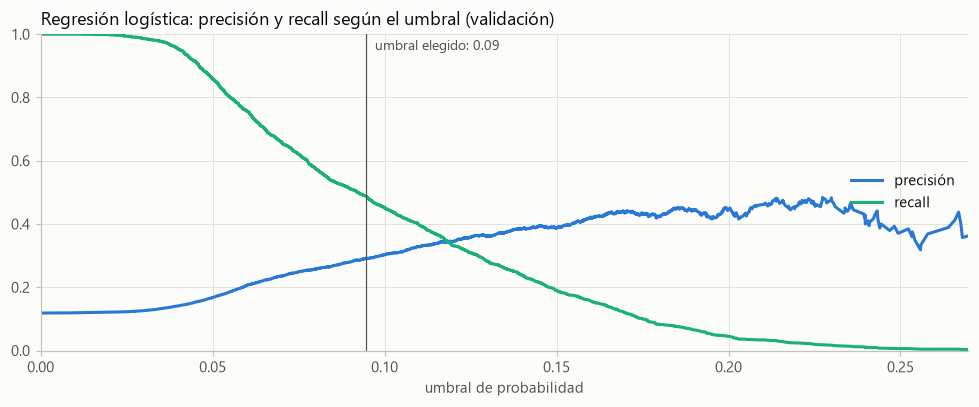

In [9]:
# Precisión y recall del mejor modelo para cada umbral posible (en validación)
precision, recall, cortes = precision_recall_curve(y_val, probs_val[mejor_nombre])
umbral = umbrales[mejor_nombre]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(cortes, precision[:-1], color=AZUL, label="precisión")
ax.plot(cortes, recall[:-1], color=AQUA, label="recall")
ax.axvline(umbral, color=TINTA_2, linewidth=0.8)
ax.annotate(f"umbral elegido: {umbral:.2f}", xy=(umbral, 0.95), xytext=(6, 0), textcoords="offset points",
            color=TINTA_2, fontsize=9)
ax.set(title=f"{mejor_nombre}: precisión y recall según el umbral (validación)", xlabel="umbral de probabilidad",
       ylim=(0, 1), xlim=(0, min(1, float(np.quantile(probs_val[mejor_nombre], 0.995)) * 1.2)))
ax.legend(loc="center right")
plt.tight_layout()
plt.show()

**¿Qué vemos?** El umbral elegido (0,095) es el punto que mejor equilibra las dos curvas. Con un umbral más bajo, el modelo detectaría casi todos los retrasos, pero la precisión bajaría a cerca del 12%: casi todas sus alertas serían falsas alarmas. Con un umbral más alto, sus alertas serían más confiables, pero se le escaparían la mayoría de los retrasos.

## 5. Modelo final: la prueba de verdad

Entrenamos el mejor modelo con **entrenamiento + validación** (de enero de 2017 a abril de 2018), mantenemos el umbral elegido en validación y lo evaluamos **una sola vez** con los datos de prueba (mayo a julio de 2018). El baseline de riesgo por estado también se recalcula con esos datos.

In [10]:
# Entrenamos el modelo final y lo comparamos con los baselines en la prueba
X_ajuste, y_ajuste = pd.concat([X_ent, X_val]), pd.concat([y_ent, y_val])
modelo_final = clone(busquedas[mejor_nombre].best_estimator_).fit(X_ajuste, y_ajuste)
baselines_finales = crear_baselines(X_ajuste, y_ajuste)

prob_pru = modelo_final.predict_proba(X_pru)[:, 1]
filas_final = [{"modelo": f"{mejor_nombre} (final)", "conjunto": "entrenamiento + validación", "umbral": umbral,
                **metricas(y_ajuste, modelo_final.predict_proba(X_ajuste)[:, 1], umbral)},
               {"modelo": f"{mejor_nombre} (final)", "conjunto": "prueba", "umbral": umbral,
                **metricas(y_pru, prob_pru, umbral)}]
filas_final += [{"modelo": nombre, "conjunto": "prueba", "umbral": umbrales[nombre],
                 **metricas(y_pru, predecir(X_pru), umbrales[nombre])}
                for nombre, predecir in baselines_finales.items()]
resultado_final = pd.DataFrame(filas_final).set_index(["modelo", "conjunto"])
resultado_final

umbral  exactitud  \
modelo                      conjunto                                        
Regresión logística (final) entrenamiento + validación   0.095      0.745   
                            prueba                       0.095      0.739   
Siempre a tiempo            prueba                       0.500      0.962   
Riesgo por estado           prueba                       0.072      0.639   

                                                        precisión  recall  \
modelo                      conjunto                                        
Regresión logística (final) entrenamiento + validación      0.160   0.547   
                            prueba                          0.080   0.557   
Siempre a tiempo            prueba                          0.000   0.000   
Riesgo por estado           prueba                          0.050   0.468   

                                                          F1   AUC  
modelo                      conjunto                                
Regresión logística (final) entrenamiento + validación 0.247 0.713  
                            prueba                     0.140 0.724  
Siempre a tiempo            prueba                     0.000 0.500  
Riesgo por estado           prueba                     0.090 0.575

In [11]:
# Matriz de confusión en la prueba: filas = lo que pasó, columnas = lo que dijo el modelo
pred_pru = (prob_pru >= umbral).astype(int)
matriz = pd.DataFrame(confusion_matrix(y_pru, pred_pru),
                      index=["llegó a tiempo", "llegó tarde"], columns=["el modelo dijo: a tiempo", "el modelo dijo: tarde"])
display(matriz)
vn, fp, fn, vp = confusion_matrix(y_pru, pred_pru).ravel()
print(f"Retrasos detectados: {vp} de {vp + fn} · falsas alarmas: {fp} · retrasos que se le escaparon: {fn}")
print(f"Riesgo promedio que predice el modelo en la prueba: {prob_pru.mean():.1%} · "
      f"porcentaje real de pedidos tarde: {y_pru.mean():.1%}")

,el modelo dijo: a tiempo,el modelo dijo: tarde
llegó a tiempo,13564,4604
llegó tarde,319,401


Retrasos detectados: 401 de 720 · falsas alarmas: 4604 · retrasos que se le escaparon: 319
Riesgo promedio que predice el modelo en la prueba: 7.9% · porcentaje real de pedidos tarde: 3.8%


**¿Qué vemos?**

- El modelo sigue **ordenando bien el riesgo** en la prueba: AUC de 0,72, contra 0,58 del riesgo por estado.
- Detectó 401 de los 720 retrasos (*recall* de 56%).
- Pero dio 4.604 falsas alarmas, así que solo el 8% de sus alertas fueron correctas y el F1 bajó de 0,37 a 0,14. La causa principal es que en la prueba casi no hubo retrasos (3,8%, contra 11,8% en validación): el umbral se eligió en un período con muchos retrasos, y en un período tranquilo queda demasiado bajo.
- Por la misma razón, el modelo predice en promedio un 7,9% de riesgo, cuando en la prueba solo llegó tarde el 3,8%: sobreestima el riesgo porque aprendió de meses con más problemas.
- Su exactitud (74%) es menor que la de «siempre a tiempo» (96%), pero ese baseline no detecta ningún retraso.

**¿Qué significa?** El modelo sirve más como un **indicador de riesgo** (qué pedidos tienen más probabilidad de atrasarse que otros) que como una predicción exacta de sí o no. Por eso en la aplicación mostramos la probabilidad y un nivel de riesgo: bajo, medio o alto.

## 6. ¿Qué variables usa más el modelo?

Igual que en el cuaderno 02, usamos la **importancia por permutación**: desordenamos al azar una variable a la vez y medimos cuánto **baja el AUC**. Si baja mucho, el modelo depende de esa variable.

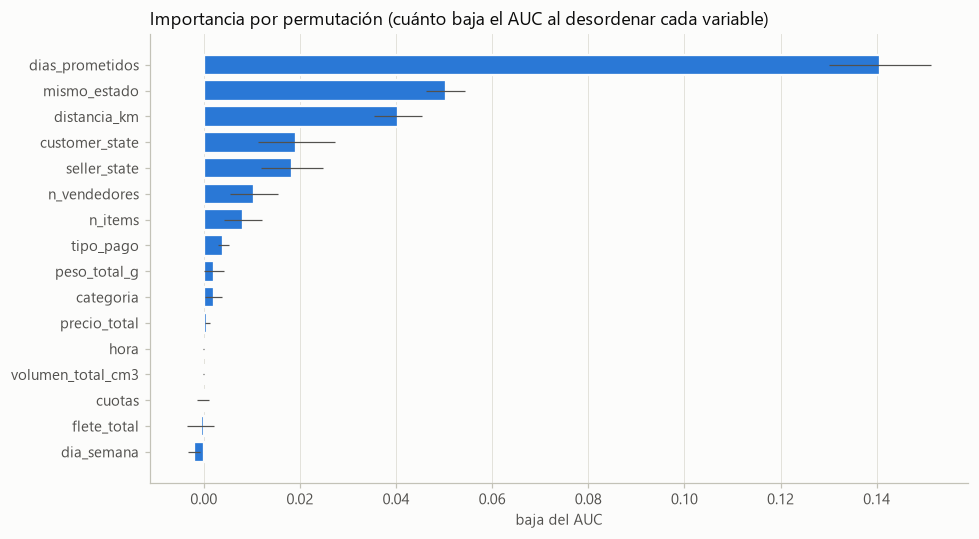

,baja del AUC,desviación
dias_prometidos,0.141,0.011
mismo_estado,0.050,0.004
distancia_km,0.040,0.005
customer_state,0.019,0.008
seller_state,0.018,0.006
n_vendedores,0.010,0.005
n_items,0.008,0.004
tipo_pago,0.004,0.001
peso_total_g,0.002,0.002
categoria,0.002,0.002


In [12]:
# Importancia por permutación de cada variable en la prueba
muestra = X_pru.sample(5000, random_state=SEMILLA)
imp = permutation_importance(modelo_final, muestra, y_pru.loc[muestra.index], scoring="roc_auc",
                             n_repeats=5, random_state=SEMILLA, n_jobs=1)
importancia = (pd.DataFrame({"baja del AUC": imp.importances_mean, "desviación": imp.importances_std},
                            index=muestra.columns)
               .sort_values("baja del AUC"))

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(importancia.index, importancia["baja del AUC"], xerr=importancia["desviación"], color=AZUL,
        edgecolor=SUPERFICIE, linewidth=1.5, error_kw=dict(ecolor=TINTA_2, elinewidth=0.8))
ax.set(title="Importancia por permutación (cuánto baja el AUC al desordenar cada variable)", xlabel="baja del AUC")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
importancia.sort_values("baja del AUC", ascending=False)

**¿Qué vemos?** La variable más importante, por lejos, son los **días prometidos**: desordenarla baja el AUC en 0,14. Tiene sentido, porque llegar tarde es llegar después de lo prometido, y cuando Olist promete pocos días es más fácil fallar. Le siguen si vendedor y cliente están en el mismo estado (0,05), la distancia (0,04) y los estados del cliente y del vendedor (0,02 cada uno). El resto casi no aporta.

## 7. Guardamos el modelo para la aplicación

Como en el cuaderno 02, **volvemos a entrenar el modelo con todos los datos** (de enero de 2017 a julio de 2018) y la misma configuración, y lo guardamos con su receta de preparación. En el archivo JSON guardamos también el **umbral** y el porcentaje promedio de retrasos, para que la aplicación pueda decir si un pedido tiene más o menos riesgo que lo normal.

In [13]:
# Reentrenamos con todos los datos y guardamos el modelo y su descripción
modelo_app = clone(modelo_final).fit(X, y)
ruta_modelo = MODELOS / "clasificacion_tarde.joblib"
joblib.dump(modelo_app, ruta_modelo, compress=3)

metricas_prueba = resultado_final.loc[(f"{mejor_nombre} (final)", "prueba")].drop("umbral").round(4).to_dict()
metadatos = {
    "modelo": mejor_nombre,
    "objetivo": OBJETIVO,
    "umbral": round(umbral, 4),
    "tasa_base": round(float(y.mean()), 4),
    "categoricas": CATEGORICAS,
    "numericas": NUMERICAS,
    "hiperparametros": {k.replace("modelo__", ""): v for k, v in busquedas[mejor_nombre].best_params_.items()},
    "entrenado_con": "todas las compras de 2017-01-05 a 2018-07-31",
    "evaluacion": "modelo entrenado con compras hasta 2018-04-30 y evaluado con compras de mayo a julio de 2018",
    "metricas_prueba": metricas_prueba,
    "version_sklearn": sklearn.__version__,
    "fecha": date.today().isoformat(),
}
(MODELOS / "clasificacion_tarde.json").write_text(json.dumps(metadatos, indent=2, ensure_ascii=False, default=str),
                                                  encoding="utf-8")
print(f"{ruta_modelo.name}: {ruta_modelo.stat().st_size / 1e6:.1f} MB")
print(json.dumps(metadatos, indent=2, ensure_ascii=False, default=str))

clasificacion_tarde.joblib: 0.0 MB
{
  "modelo": "Regresión logística",
  "objetivo": "tarde",
  "umbral": 0.0945,
  "tasa_base": 0.0684,
  "categoricas": [
    "customer_state",
    "seller_state",
    "categoria",
    "tipo_pago",
    "dia_semana"
  ],
  "numericas": [
    "distancia_km",
    "mismo_estado",
    "dias_prometidos",
    "flete_total",
    "precio_total",
    "peso_total_g",
    "volumen_total_cm3",
    "n_items",
    "n_vendedores",
    "cuotas",
    "hora"
  ],
  "hiperparametros": {
    "C": 0.01
  },
  "entrenado_con": "todas las compras de 2017-01-05 a 2018-07-31",
  "evaluacion": "modelo entrenado con compras hasta 2018-04-30 y evaluado con compras de mayo a julio de 2018",
  "metricas_prueba": {
    "exactitud": 0.7394,
    "precisión": 0.0801,
    "recall": 0.5569,
    "F1": 0.1401,
    "AUC": 0.7238
  },
  "version_sklearn": "1.9.1",
  "fecha": "2026-11-15"
}


In [14]:
# Probamos el modelo guardado con el mismo pedido de ejemplo del cuaderno 02 (de São Paulo a Río de Janeiro)
modelo_cargado = joblib.load(ruta_modelo)
assert np.allclose(modelo_cargado.predict_proba(X_pru)[:, 1], modelo_app.predict_proba(X_pru)[:, 1])
pedido_nuevo = pd.DataFrame([{
    "customer_state": "RJ", "seller_state": "SP", "categoria": "bed_bath_table", "tipo_pago": "credit_card",
    "dia_semana": 2, "distancia_km": 360.0, "mismo_estado": 0, "dias_prometidos": 20.0,
    "flete_total": 18.5, "precio_total": 120.0, "peso_total_g": 1200, "volumen_total_cm3": 9000,
    "n_items": 1, "n_vendedores": 1, "cuotas": 3, "hora": 15,
}])
prob = modelo_cargado.predict_proba(pedido_nuevo[metadatos["categoricas"] + metadatos["numericas"]])[0, 1]
print(f"Probabilidad de llegar tarde: {prob:.1%} (promedio general: {metadatos['tasa_base']:.1%}) -> "
      f"{'TARDE' if prob >= metadatos['umbral'] else 'a tiempo'} con el umbral de {metadatos['umbral']:.2f}")

Probabilidad de llegar tarde: 19.7% (promedio general: 6.8%) -> TARDE con el umbral de 0.09


## 8. Conclusiones

**Resumen del modelo**

| | |
|---|---|
| Algoritmo elegido | Regresión logística con regularización fuerte (`C` = 0,01) |
| Cómo lo elegimos | búsqueda en malla con validación cruzada temporal de 4 rondas, buscando el mayor AUC |
| Umbral | 0,095, el de mejor F1 en validación |
| Validación | AUC 0,75 · F1 0,37 · *recall* 49% (riesgo por estado: AUC 0,64 · F1 0,31) |
| Prueba | AUC 0,72 · F1 0,14 · *recall* 56% · precisión 8% (riesgo por estado: AUC 0,58 · F1 0,09) |

**¿Qué significa?** Predecir retrasos es difícil: ninguna variable por sí sola los explica bien y su frecuencia cambia mucho de un mes a otro. Nuestro modelo ordena el riesgo mejor que las alternativas simples, pero en un período con pocos retrasos da muchas falsas alarmas.

**Limitaciones**

- El umbral depende de cuántos retrasos haya en el período: uno elegido en meses con muchos retrasos queda bajo en meses tranquilos.
- Los retrasos dependen de eventos que no están en los datos, como huelgas, clima o problemas del transportista.

**¿Cómo se podría mejorar?**

- Ajustar el umbral cada cierto tiempo con datos recientes, o usar el modelo para marcar solo el 10% de pedidos más riesgosos.
- Volver a entrenarlo con los datos más nuevos (para la aplicación ya lo entrenamos con todos los datos hasta julio de 2018).
- Agregar información del vendedor o del transportista, por ejemplo cuántos retrasos tuvo antes.

**Archivos para la aplicación:** `models/clasificacion_tarde.joblib` y `models/clasificacion_tarde.json` (incluye el umbral y el porcentaje promedio de retrasos).